In [1]:
if (!requireNamespace("mixOmics", quietly = TRUE)) {
    options(BioC_mirror = "https://bioconductor.org")
    BiocManager::install(version = "3.18", force = TRUE)
    BiocManager::install("mixOmics")
}

library(mixOmics)
library(BiocParallel)

# print mixomics version
packageVersion("mixOmics")

Loading required package: MASS

Loading required package: lattice

Loading required package: ggplot2


Loaded mixOmics 6.26.0
Thank you for using mixOmics!
Tutorials: http://mixomics.org
Bookdown vignette: https://mixomicsteam.github.io/Bookdown
Questions, issues: Follow the prompts at http://mixomics.org/contact-us
Cite us:  citation('mixOmics')




[1] ‘6.26.0’

In [2]:
DATA_DIR <- "/home/mariya/Data/pallas"
TRAIN_DATA_DIR <- file.path(DATA_DIR, "mlomix_datasets/train-bimodal-reduced")
METH_TRAIN_FILE <- file.path(TRAIN_DATA_DIR, "features.dnam.csv")
GEX_TRAIN_FILE <- file.path(TRAIN_DATA_DIR, "features.gex.csv")
LABELS_TRAIN_FILE <- file.path(TRAIN_DATA_DIR, "labels.csv")
OUTPUT_DIR <- file.path(DATA_DIR, "mixOmics")

In [3]:
source("helpers.R")
train_data <- data(GEX_TRAIN_FILE, METH_TRAIN_FILE, LABELS_TRAIN_FILE)

Samples: 868 
GEX features: 4560 
DNAm features: 6582 
Subtypes: AML, APL-PML::RARA AML, CBFA2T3::GLIS2 AML, CBFB::MYH11 AML, CEBPAalt AML, DEK::NUP214 AML, ETV6-r AML, FUS::ERG AML, KAT6A-r AML, KMT2A-r AML, NPM1alt AML, NUP98-r AML, PICALM::MLLT10 AML, RUNX1::RUNX1T1 B-ALL, BCR::ABL1 B-ALL, BCR::ABL1-like B-ALL, DUX4-r B-ALL, ETV6::RUNX1 B-ALL, ETV6::RUNX1-like B-ALL, high hyperdiploid B-ALL, iAMP21 B-ALL, KMT2A-r B-ALL, MEF2D-r B-ALL, PAX5 P80R B-ALL, PAX5alt B-ALL, TCF3::PBX1 B-ALL, ZNF384-r Non-leukemic T-ALL 


In [4]:
X_gex_train <- train_data$X_gex
X_dnam_train <- train_data$X_dnam
Y_train     <- train_data$Y

head(X_gex_train)
head(X_dnam_train)
head(Y_train)

,ENSG00000126882,ENSG00000067177,ENSG00000178795,ENSG00000080546,ENSG00000116731,ENSG00000248329,ENSG00000185658,ENSG00000145113,ENSG00000276644,ENSG00000117266,⋯,ENSG00000136709,ENSG00000124608,ENSG00000221944,ENSG00000056972,ENSG00000119965,ENSG00000188419,ENSG00000137824,ENSG00000137941,ENSG00000213463,ENSG00000103264
ALL_1000,4.7549540,1.2341500,-1.596042,5.272428,7.050687,13.046647,5.860757,-0.1403364,-0.4762257,3.949196,⋯,4.173172,3.632939,2.025743,6.426367,0.8157554,2.234748,4.059503,-1.090650,2.669294,4.250851
ALL_1003,0.2705202,-1.2468383,-1.596042,4.325985,8.510442,-1.596042,5.555093,-0.7255331,-1.2101641,4.918563,⋯,4.638274,3.515001,3.370149,7.188021,1.9904844,1.614775,4.351424,-1.277905,3.714383,4.572531
ALL_1005,1.9079234,-1.2297735,-1.596042,2.679394,5.751903,-1.596042,5.672022,2.0149281,-1.5960423,4.377423,⋯,5.147579,4.722669,4.159888,5.738195,4.2917781,4.289182,3.352034,-1.596042,4.784597,3.463765
ALL_1019,5.1539926,-1.2768282,-1.596042,4.597364,6.367301,-1.596042,5.387009,-0.2970125,-0.6174198,4.448343,⋯,4.386659,4.834313,2.733588,5.666214,3.1749083,3.633639,3.918076,-1.139919,3.519865,3.388007
ALL_1031,4.3650435,-0.8894692,9.640338,5.104924,6.982794,-1.596042,5.879424,2.4014250,-1.4868522,4.503498,⋯,4.553150,5.210408,2.501390,6.824654,3.2949106,4.407599,4.959919,-1.424180,4.462839,3.916243
ALL_1039,5.3817603,-1.2207872,10.718481,7.086583,7.970225,-1.596042,5.390438,5.9114389,1.6236913,4.231144,⋯,4.344614,3.986922,3.390426,6.446533,2.2597522,3.043559,4.032352,-1.253907,3.797949,3.043019


,cg17259886,cg13293524,cg16288865,cg12923179,cg11622162,cg07232063,cg03763508,cg18638389,cg02707071,cg08166720,⋯,cg19557110,cg08911692,cg05807885,cg00527174,cg08473752,cg08870143,cg06814191,cg06710207,cg08523727,cg06671690
ALL_1000,0.9628,0.9734,0.2669,0.9124,0.0519,0.8871,0.9589,0.9350,0.9530,0.9419,⋯,0.9679,0.9551,0.0817,0.0413,0.9560,0.9348,0.9375,0.9353,0.1773,0.3090
ALL_1003,0.9543,0.9784,0.9405,0.9111,0.0512,0.9138,0.9501,0.9287,0.9587,0.9059,⋯,0.9557,0.9493,0.0343,0.1358,0.9543,0.9377,0.9402,0.9389,0.8985,0.0131
ALL_1005,0.9567,0.9688,0.9195,0.9326,0.0571,0.9326,0.8014,0.9232,0.9447,0.9334,⋯,0.9486,0.9413,0.5024,0.0513,0.9357,0.9436,0.9134,0.9285,0.5752,0.2365
ALL_1019,0.9406,0.9741,0.9442,0.9032,0.0394,0.6195,0.9358,0.9481,0.9608,0.4691,⋯,0.9561,0.9526,0.0308,0.1097,0.9293,0.9478,0.9392,0.8979,0.9337,0.0127
ALL_1031,0.9483,0.9751,0.9297,0.9276,0.0503,0.8530,0.9576,0.9438,0.9563,0.9559,⋯,0.9623,0.9613,0.3448,0.0494,0.9553,0.6602,0.9439,0.9418,0.9432,0.0560
ALL_1039,0.9539,0.9782,0.9439,0.9222,0.0484,0.9325,0.9549,0.9351,0.9427,0.9470,⋯,0.9541,0.9524,0.1041,0.0670,0.9273,0.6549,0.8594,0.9298,0.9235,0.0121


[1] B-ALL, DUX4-r         B-ALL, PAX5alt        B-ALL, MEF2D-r       
[4] B-ALL, ZNF384-r       B-ALL, BCR::ABL1-like B-ALL, BCR::ABL1     
28 Levels: AML, APL-PML::RARA AML, CBFA2T3::GLIS2 ... T-ALL

In [5]:
FOLDS     <- 3
NREPEAT   <- 10
NCOMP     <- 35
DIST      <- "max.dist"
bpparam <- MulticoreParam(workers = parallel::detectCores() - 1)

keepx_grid <- c(20, 100, 200, 300)
keepx_grid


[1]  20 100 200 300

comp1  comp2  comp3  comp4  comp5  comp6  comp7  comp8  comp9 comp10 comp11 
    20     20    200    300    100    100    200    300    200    300     20 
comp12 comp13 comp14 comp15 comp16 comp17 comp18 comp19 comp20 comp21 comp22 
    20     20    100    100    200    200    200    100     20    100    100 
comp23 comp24 comp25 comp26 comp27 comp28 comp29 comp30 comp31 comp32 comp33 
   100    100    200    100    100    100    200    300    200    300    300 
comp34 comp35 
   200    100

,comp1,comp2,comp3,comp4,comp5,comp6,comp7,comp8,comp9,comp10,⋯,comp26,comp27,comp28,comp29,comp30,comp31,comp32,comp33,comp34,comp35
nrep.1,0.9285714,0.8921654,0.8502985,0.8243676,0.7932887,0.7534648,0.7208119,0.6825550,0.6339754,0.6187914,⋯,0.2880655,0.2587279,0.2357558,0.2406605,0.2051427,0.2143007,0.2107461,0.1792712,0.1686717,0.1858495
nrep.2,0.9293275,0.8924174,0.8598394,0.8253654,0.7989689,0.7545534,0.7250123,0.6746824,0.6305738,0.6299348,⋯,0.2932834,0.2420555,0.2260720,0.2109331,0.2268511,0.1825998,0.1879481,0.1859850,0.1810223,0.1796620
nrep.3,0.9285714,0.8920934,0.8636698,0.8272523,0.7989524,0.7606421,0.7269767,0.6740306,0.6378727,0.6191370,⋯,0.2603554,0.2382479,0.2252060,0.2081872,0.2083618,0.1787847,0.1767547,0.1686714,0.1712071,0.1632708
nrep.4,0.9285714,0.8967083,0.8534712,0.8391909,0.7996236,0.7648014,0.7237201,0.6815312,0.6362260,0.6220985,⋯,0.2660929,0.2991786,0.2385418,0.2231316,0.2411460,0.2138295,0.1707441,0.1977533,0.1774957,0.1465058
nrep.5,0.9285714,0.8900119,0.8630382,0.8202616,0.7988055,0.7625309,0.7197745,0.6807884,0.6434494,0.6134990,⋯,0.2763102,0.2725727,0.2516906,0.2315840,0.2041234,0.1827782,0.1875816,0.1840663,0.1998645,0.1752578
nrep.6,0.9293275,0.8934975,0.8628728,0.8154946,0.7905994,0.7548444,0.7199048,0.6750131,0.6387759,0.6192218,⋯,0.2810331,0.2444116,0.2367338,0.2251682,0.2223336,0.1862041,0.1609086,0.1697883,0.1860741,0.1910332
nrep.7,0.9285714,0.8865490,0.8621910,0.8296865,0.7955293,0.7550513,0.7234403,0.6838690,0.6403037,0.6159383,⋯,0.2813381,0.2461833,0.2342116,0.2055721,0.2213209,0.2116610,0.1826203,0.1968221,0.1825100,0.1953132
nrep.8,0.9293275,0.8938442,0.8574564,0.8245806,0.7964360,0.7609107,0.7090314,0.6836303,0.6362794,0.6139440,⋯,0.2788719,0.2455394,0.2209294,0.2281380,0.1899485,0.1859659,0.2076085,0.1842349,0.1653818,0.1929324
nrep.9,0.9293275,0.8920934,0.8557386,0.8250390,0.8015023,0.7647359,0.7203526,0.6694866,0.6422786,0.6213400,⋯,0.2786117,0.2520747,0.2302570,0.2028347,0.1925132,0.1691361,0.2230292,0.1905283,0.1984215,0.1644861
nrep.10,0.9285714,0.8920934,0.8464631,0.8193500,0.7932783,0.7640204,0.7269367,0.6839111,0.6329794,0.6154145,⋯,0.2673225,0.2375465,0.2454389,0.2377243,0.2376574,0.2211084,0.2168046,0.1644475,0.1625458,0.1784848


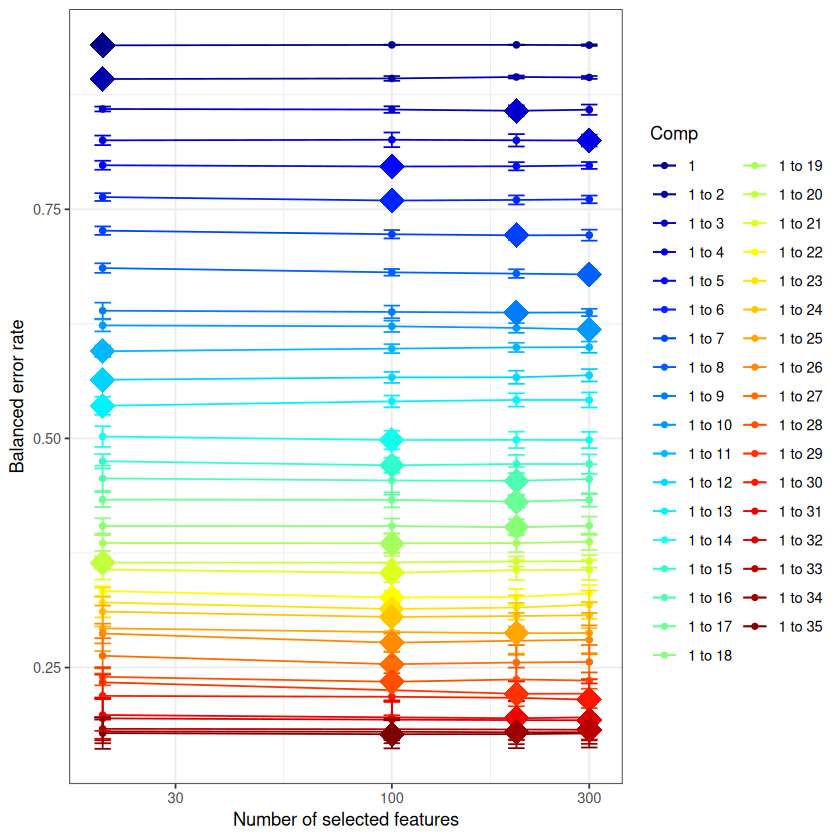

In [6]:

gex_tune <- tune.splsda(
  X_gex_train,
  Y_train,
  ncomp = NCOMP,
  test.keepX = keepx_grid,
  validation = "Mfold",
  folds = FOLDS,
  nrepeat = NREPEAT,
  dist = DIST,
  measure = "BER",
  cpus = parallel::detectCores() - 1,
  progressBar = FALSE
)

gex_tune$choice.keepX
gex_tune$choice.ncomp
plot(gex_tune)
saveRDS(gex_tune,    file.path(OUTPUT_DIR, "gex_tune_X.rds"))

comp1  comp2  comp3  comp4  comp5  comp6  comp7  comp8  comp9 comp10 comp11 
   300    300     20    300    300    300    200    300    200    100    200 
comp12 comp13 comp14 comp15 comp16 comp17 comp18 comp19 comp20 comp21 comp22 
   300    200    100    100     20    100    100    100     20    100     20 
comp23 comp24 comp25 comp26 comp27 comp28 comp29 comp30 comp31 comp32 comp33 
    20     20     20     20     20     20    100    200     20    100     20 
comp34 comp35 
   100    100

,comp1,comp2,comp3,comp4,comp5,comp6,comp7,comp8,comp9,comp10,⋯,comp26,comp27,comp28,comp29,comp30,comp31,comp32,comp33,comp34,comp35
nrep.1,0.9296875,0.8958240,0.8679933,0.8312488,0.8078009,0.7570793,0.7355716,0.6981281,0.6651673,0.6510513,⋯,0.2806687,0.2455836,0.2371961,0.2085653,0.1951934,0.1679188,0.1864486,0.1655331,0.1727741,0.1422973
nrep.2,0.9296875,0.8977321,0.8675930,0.8368720,0.8023781,0.7631002,0.7359468,0.6992684,0.6708141,0.6388655,⋯,0.2674143,0.2480269,0.2352583,0.2208092,0.1989569,0.1609399,0.1595827,0.1803188,0.1495235,0.1696907
nrep.3,0.9304435,0.8958240,0.8693278,0.8331676,0.7851338,0.7519249,0.7275512,0.7008468,0.6795454,0.6468285,⋯,0.2838288,0.2546419,0.2173130,0.2096941,0.1994887,0.1953485,0.1998538,0.1642562,0.1531942,0.1822587
nrep.4,0.9296875,0.8958240,0.8687091,0.8277608,0.7963845,0.7616389,0.7263289,0.6948535,0.6728622,0.6369895,⋯,0.2688775,0.2624435,0.2275649,0.2310744,0.1930676,0.1753708,0.1721661,0.1513417,0.1598788,0.1268136
nrep.5,0.9293275,0.8958240,0.8693278,0.8299443,0.7913945,0.7576232,0.7270541,0.7003998,0.6764565,0.6442188,⋯,0.3096508,0.2860457,0.2499480,0.2031330,0.1966207,0.1771858,0.1747332,0.1847250,0.1533964,0.1540897
nrep.6,0.9296875,0.8965800,0.8678142,0.8315023,0.8013916,0.7577216,0.7193287,0.6919878,0.6758173,0.6474522,⋯,0.2790329,0.2588400,0.2407694,0.2075535,0.2073657,0.1932643,0.1977185,0.1797526,0.1284971,0.1197746
nrep.7,0.9296875,0.8959974,0.8699851,0.8329717,0.7927432,0.7584049,0.7202489,0.7046832,0.6739036,0.6561228,⋯,0.2676055,0.2543428,0.2456898,0.2229021,0.1946897,0.1782846,0.1664244,0.1561746,0.1307900,0.1576900
nrep.8,0.9296875,0.8958240,0.8690197,0.8429147,0.7971492,0.7494591,0.7221643,0.7039369,0.6750815,0.6557723,⋯,0.2898970,0.2703295,0.2276820,0.2167134,0.1945774,0.1877756,0.1659141,0.1644338,0.1541946,0.1750326
nrep.9,0.9296875,0.8958240,0.8677664,0.8363892,0.8014315,0.7615979,0.7320212,0.6918408,0.6629201,0.6495498,⋯,0.2708106,0.2534205,0.2448797,0.1980904,0.1966195,0.1728436,0.1515011,0.1539375,0.1399603,0.1421096
nrep.10,0.9293275,0.8958240,0.8657118,0.8213386,0.7911508,0.7513661,0.7219027,0.6964282,0.6654548,0.6346143,⋯,0.2880367,0.2574632,0.2525565,0.1995052,0.1906470,0.1831978,0.1750633,0.1672711,0.1635947,0.1491050


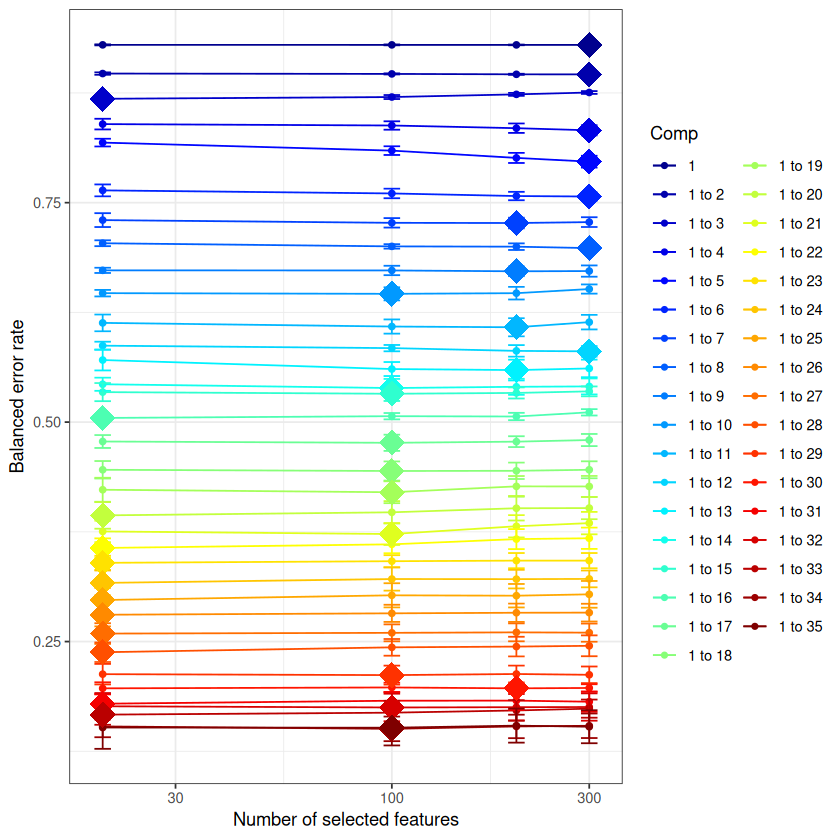

In [7]:

dnam_tune <- tune.splsda(
  X_dnam_train,
  Y_train,
  ncomp = NCOMP,
  test.keepX = keepx_grid,
  validation = "Mfold",
  folds = FOLDS,
  nrepeat = NREPEAT,
  dist = DIST,
  measure = "BER",
  cpus = parallel::detectCores() - 1,
  progressBar = FALSE
)

dnam_tune$choice.keepX
dnam_tune$choice.ncomp
plot(dnam_tune)
saveRDS(dnam_tune,    file.path(OUTPUT_DIR, "dnam_tune_X.rds"))

Design matrix has changed to include Y; each block will be
            linked to Y.


You have provided a sequence of keepX of length: 4 for block GEX and 4 for block DNAm.
This results in 16 models being fitted for each component and each nrepeat, this may take some time to run, be patient!

R_zmq_msg_send errno: 4 strerror: Interrupted system call


R_zmq_msg_send errno: 4 strerror: Interrupted system call


R_zmq_msg_send errno: 4 strerror: Interrupted system call


R_zmq_msg_send errno: 4 strerror: Interrupted system call


R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call


R_zmq_msg_send errno: 4 strerror: Interrupted system call


R_zmq_msg_send errno: 4 strerror: Interrupted system call


R_zmq_msg_send errno: 4 strerror: Interrupted system call


R_zmq_msg_send errno: 4 strerror: Interrupted system call


R_zmq_msg_send errno: 4 strerror: Interrupted syst

$GEX
 [1] 300  20  20 100  20  20  20 300 300 100 300 100 100 100 100 200  20 200 100
[20]  20 200 100 100 200 100 300 100 300 200 100 300 300 100 300 300

$DNAm
 [1] 100 300 100 300 200 300  20  20 300 300 300  20 100  20  20  20 200  20  20
[20]  20 100  20 200  20  20  20  20  20  20 300  20  20  20  20 100

,comp1,comp2,comp3,comp4,comp5,comp6,comp7,comp8,comp9,comp10,⋯,comp26,comp27,comp28,comp29,comp30,comp31,comp32,comp33,comp34,comp35
nrep.1,0.9300835,0.8949479,0.8482549,0.8281843,0.7808302,0.7507836,0.7193576,0.6881293,0.6430042,0.6238834,⋯,0.2682273,0.2328654,0.1943220,0.2014945,0.1988576,0.1913147,0.1832143,0.1769652,0.1740891,0.2027185
nrep.2,0.9300835,0.8949479,0.8567017,0.8189542,0.7928714,0.7513899,0.7235411,0.6787739,0.6372001,0.6222708,⋯,0.2387573,0.2284094,0.2063188,0.2060276,0.1874020,0.2009048,0.1886923,0.1877854,0.1838877,0.1662178
nrep.3,0.9289675,0.8813750,0.8450726,0.8196425,0.7999054,0.7637683,0.7128009,0.6718956,0.6549905,0.6171158,⋯,0.2133100,0.2534087,0.2119683,0.2406251,0.2075600,0.1508594,0.1773958,0.1668195,0.2111628,0.1707413
nrep.4,0.9293275,0.8951213,0.8485652,0.8325562,0.7837891,0.7529490,0.7092840,0.6860111,0.6323289,0.6227475,⋯,0.2289341,0.2235668,0.2223792,0.2255650,0.1887396,0.2023601,0.2138693,0.1808431,0.1686885,0.1884108
nrep.5,0.9289315,0.8811656,0.8568207,0.8265982,0.7929484,0.7553385,0.7154580,0.6778745,0.6344442,0.6134015,⋯,0.2549131,0.2327011,0.2149360,0.1849937,0.1858703,0.1626983,0.1946838,0.1975496,0.1967981,0.1526778
nrep.6,0.9233871,0.8856659,0.8475366,0.8185290,0.7889719,0.7506301,0.7136213,0.6794195,0.6386247,0.6135025,⋯,0.2473050,0.2322313,0.2383686,0.2197471,0.2264646,0.2036334,0.2045638,0.1681775,0.1769384,0.1801277
nrep.7,0.9300835,0.8861207,0.8614420,0.8234223,0.7890203,0.7540711,0.7123778,0.6770828,0.6274454,0.6257912,⋯,0.2421518,0.2543705,0.2561133,0.2454528,0.1875473,0.1857232,0.1988725,0.1940726,0.1730339,0.1541475
nrep.8,0.9289675,0.8848312,0.8499490,0.8273794,0.7881127,0.7472606,0.7242023,0.6770795,0.6456661,0.6122291,⋯,0.2727385,0.2590672,0.2260312,0.2065541,0.1676199,0.1937791,0.1716881,0.1767466,0.1504870,0.1780965
nrep.9,0.9289675,0.8756867,0.8458981,0.8163945,0.7820057,0.7581508,0.7022957,0.6741888,0.6438155,0.6224208,⋯,0.2325443,0.2637515,0.2520897,0.1947869,0.2010982,0.1911940,0.2258281,0.1587676,0.1697127,0.1761463
nrep.10,0.9300835,0.8824911,0.8541350,0.8156190,0.7829802,0.7563085,0.7118872,0.6842276,0.6450651,0.6116221,⋯,0.2861855,0.2583236,0.2410719,0.2213388,0.1819500,0.1861709,0.1649801,0.2044924,0.1697691,0.1668684


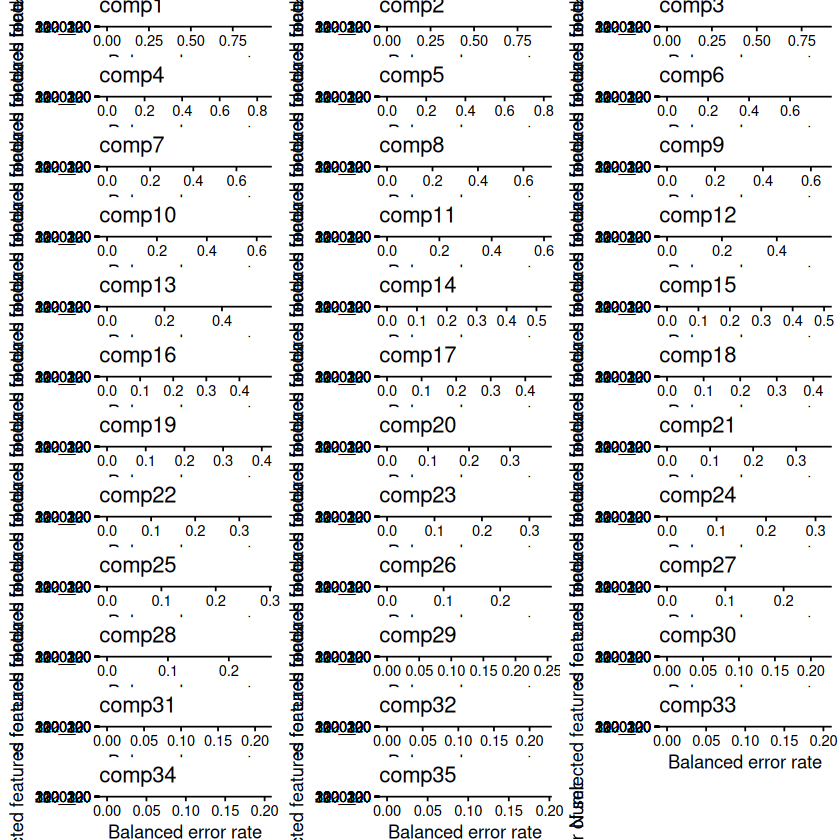

In [8]:
FOLDS     <- 3
NREPEAT   <- 10
NCOMP     <- 35
DIST      <- "max.dist"
bpparam <- MulticoreParam(workers = parallel::detectCores() - 1)

blocks_train <- list(GEX = X_gex_train, DNAm = X_dnam_train)
# ============================================================
design       <- matrix(0.1, nrow = 2, ncol = 2,
                       dimnames = list(c("GEX","DNAm"), c("GEX","DNAm")))

# coarse grid (adjust values / step as needed)
test.keepX <- list(
  GEX  = keepx_grid,
  DNAm = keepx_grid
)

diablo_tune <- tune.block.splsda(
  X = blocks_train,              # list(GEX = X_gex_train, DNAm = X_dnam_train)
  Y = Y_train,
  ncomp = NCOMP,             # or a reasonable max (e.g. components = nclass-1 + extra)
  test.keepX = test.keepX,
  validation = "Mfold",
  folds = FOLDS,
  nrepeat = NREPEAT,
  dist = DIST,
  measure = "BER",               # good for imbalanced classes
  BPPARAM = bpparam,
  progressBar = FALSE,
  design = design
)

# inspect chosen sparsity
diablo_tune$choice.keepX
diablo_tune$choice.ncomp
plot(diablo_tune)
saveRDS(diablo_tune, file.path(OUTPUT_DIR, "diablo_tune.rds"))